# Ensembles of Decision Trees
Follow _Introduction to Machine Learning_ [Chapter 2 Supervised Learning](https://github.com/amueller/introduction_to_ml_with_python/blob/master/02-supervised-learning.ipynb) **2.3.6 Ensembles of Decision Trees** (p.85)

> Ensembles are methods that combine multiple machine learning models to create more powerful models.

### Random Forest
Many, different, parallel decision trees are built, soft-voting (classification) or average (regression) is used

Powerful, relatively easy to train, robust, parallelizable training, costly in prediction (many trees)

### Gradient boosted trees
A sequence of decision trees is built, each trained to correct the errors of the previous

Powerful, a bit harder to train than random forest, XGBoost (a variant) wins many Kaggle competitions, costly in training, faster prediction

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
import mglearn

## Random Forest 

What is random? 
1. Data points to train trees is randomly selected from data using bootstrap sampling (sampling with replacement).
2. A subset of features is randomly selected to find the best split.

Parameters:
- `n_estimators` the number of trees (not tuned, more is better).
- `max_features` maximum number of features that can be selected to determine split.
- `max_depth` maximum number of tree levels. Stops tree growth.
- `min_samples_leaf` minimum number of samples required to be a leaf node. Stops tree growth.


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=100, noise=0.25, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y,
                                                    random_state=42)

forest = RandomForestClassifier(n_estimators=5, random_state=2)
forest.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

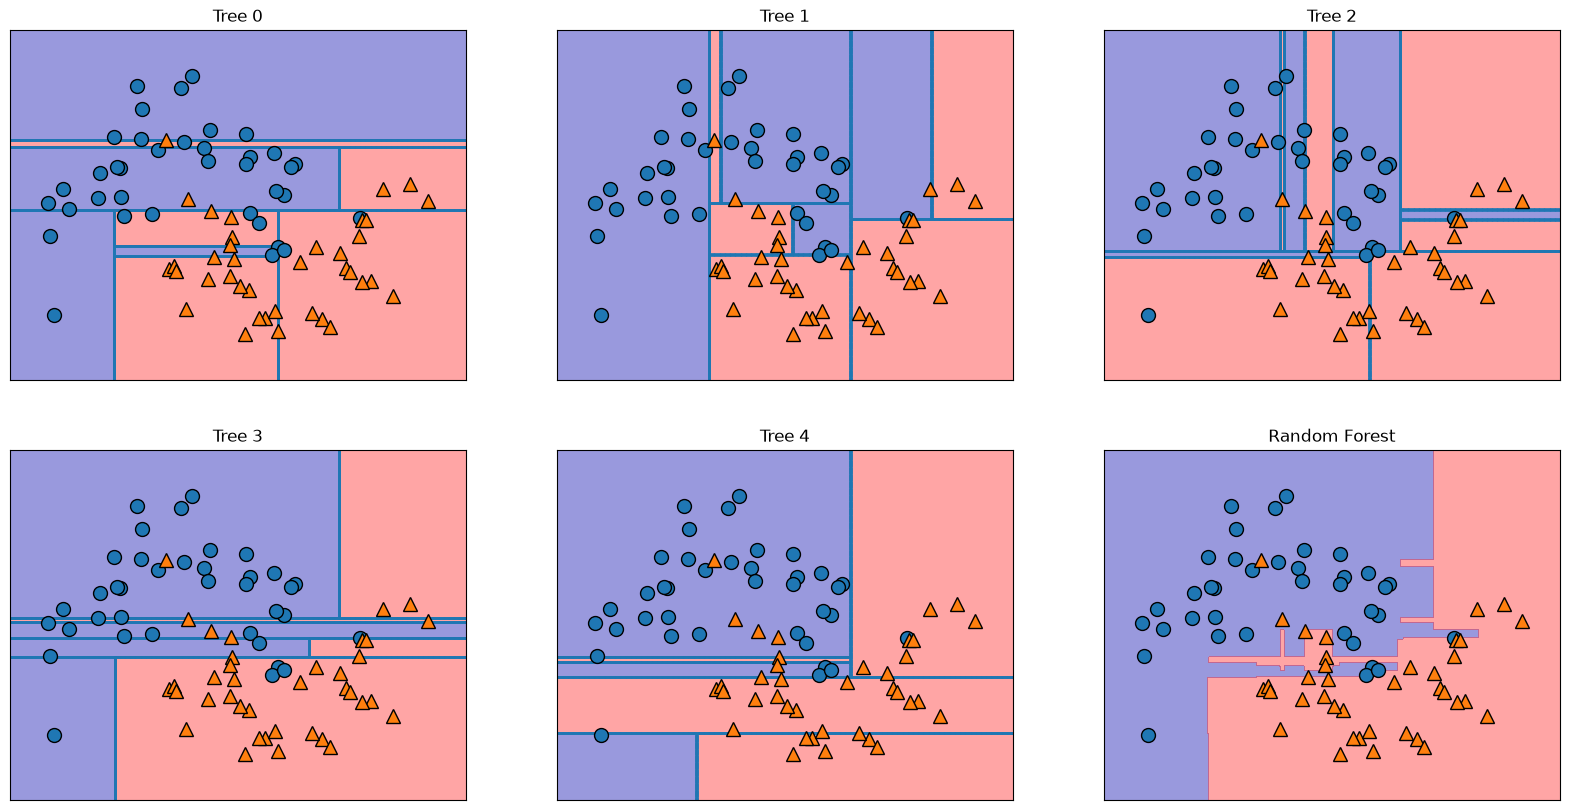

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for i, (ax, tree) in enumerate(zip(axes.ravel(), forest.estimators_)):
    ax.set_title("Tree {}".format(i))
    mglearn.plots.plot_tree_partition(X_train, y_train, tree, ax=ax)
    
mglearn.plots.plot_2d_separator(forest, X_train, fill=True, ax=axes[-1, -1],
                                alpha=.4)
axes[-1, -1].set_title("Random Forest")
mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train)

Decision boundaries for each tree is slightly different

Random forest overfits less than individual trees

More trees would result in smoother decision boundaries

### Random forest classification of breast cancer dataset

In [16]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

X_train, X_val, y_train, y_val = train_test_split(
    cancer.data, cancer.target, random_state=0)
forest = RandomForestClassifier(random_state=0)
forest.fit(X_train, y_train)

print("Accuracy on training set: {:.3f}".format(forest.score(X_train, y_train)))
print("Accuracy on validation set: {:.3f}".format(forest.score(X_val, y_val)))

Accuracy on training set: 1.000
Accuracy on validation set: 0.972


Using the default parameters, we get better performance than linear models (validation accuracy = 0.965) and using a single decision tree (validation accuracy = 0.951)

We might be overfitting as the training accuracy is at 100%

**Question:** How can we reduce model complexity?

**Answer:** ...


Looking at aggregated feature importances, these look more reliable. More features have non-zero importances.

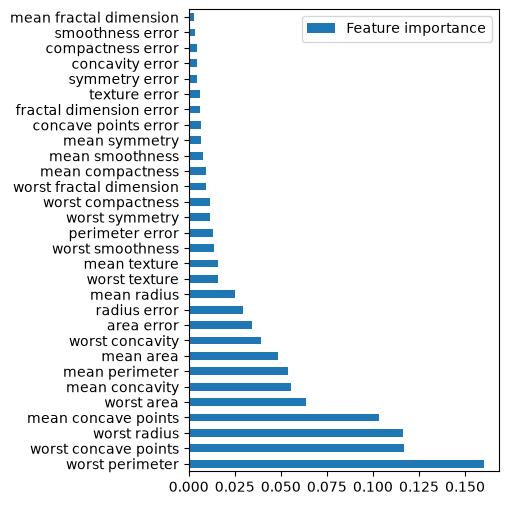

In [17]:
def plot_feature_importances_cancer(model, figsize=(4,6)):
    importances = pd.DataFrame({'Feature importance': model.feature_importances_}, 
                           index=cancer.feature_names).sort_values(by='Feature importance',ascending=False)
    importances.plot.barh(figsize=figsize);

plot_feature_importances_cancer(forest)

## Gradient Boosted Trees 

Trees are build in series, each tree trying to correct mistakes made by the previous tree

A new parameter `learning_rate` controls how much each tree tries to correct the previous. **Higher** `learning_rate` means **larger** corrections are possible, resulting in **more** complex models

Generally, shallow trees are used. This results in an ensemble of *weak learners*

In [24]:
from sklearn.ensemble import GradientBoostingClassifier

X_train, X_val, y_train, y_val = train_test_split(
    cancer.data, cancer.target, random_state=0)

gbrt = GradientBoostingClassifier(max_depth=3, n_estimators=50, random_state=0)
gbrt.fit(X_train, y_train)

print("Accuracy on training set: {:.3f}".format(gbrt.score(X_train, y_train)))
print("Accuracy on validation set: {:.3f}".format(gbrt.score(X_val, y_val)))

Accuracy on training set: 1.000
Accuracy on validation set: 0.972


Just like with Random Forest, with the default parameters, we might be overfitting

We can pre-prune by reducing the maximum depth to reduce complexity:


In [25]:
gbrt = GradientBoostingClassifier(random_state=0, max_depth=1)
gbrt.fit(X_train, y_train)

print("Accuracy on training set: {:.3f}".format(gbrt.score(X_train, y_train)))
print("Accuracy on validation set: {:.3f}".format(gbrt.score(X_val, y_val)))

Accuracy on training set: 0.991
Accuracy on validation set: 0.972


Or reduce `learning_rate`:

In [28]:
gbrt = GradientBoostingClassifier(random_state=0, learning_rate=1)
gbrt.fit(X_train, y_train)

print("Accuracy on training set: {:.3f}".format(gbrt.score(X_train, y_train)))
print("Accuracy on validation set: {:.3f}".format(gbrt.score(X_val, y_val)))

Accuracy on training set: 1.000
Accuracy on validation set: 0.951


### Feature importance of gradient boosted classifier

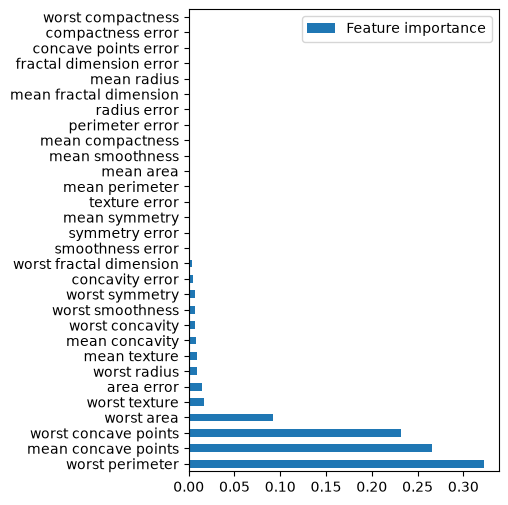

In [11]:
gbrt = GradientBoostingClassifier(random_state=0, max_depth=1)
gbrt.fit(X_train, y_train)

plot_feature_importances_cancer(gbrt)

Some features are completely ignored by the boosted tree classifier